# German power market in 2025: what the ENTSO-E data shows

First look at real data for the DE-LU bidding zone and its neighbours, before building the model.
This is the input and validation data for study block 1 (does the model reproduce 2025?).

Data: ENTSO-E Transparency Platform, downloaded with `entsoe-py` and cached in `data/raw/`.

In [58]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))
import entsoe_data as ed

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

YEAR = 2025
client = ed.get_client()

## 1. Download data

The first run takes a few minutes. Later runs read the CSV files from `data/raw/`.

In [59]:
prices_de = ed.day_ahead_prices(client, "DE_LU", YEAR)
load_de = ed.load(client, "DE_LU", YEAR)
gen_de = ed.generation(client, "DE_LU", YEAR)

print(f"Prices:     {len(prices_de)} hours")
print(f"Load:       {len(load_de)} hours")
print(f"Generation: {gen_de.shape[0]} hours, {gen_de.shape[1]} technologies")

Generation DE_LU 2025-01 ... done
Generation DE_LU 2025-02 ... done
Generation DE_LU 2025-03 ... done
Generation DE_LU 2025-04 ... done
Generation DE_LU 2025-05 ... done
Generation DE_LU 2025-06 ... done
Generation DE_LU 2025-07 ... done
Generation DE_LU 2025-08 ... done
Generation DE_LU 2025-09 ... done
Generation DE_LU 2025-10 ... done
Generation DE_LU 2025-11 ... done
Generation DE_LU 2025-12 ... done
Prices:     8760 hours
Load:       8760 hours
Generation: 8760 hours, 16 technologies


In [60]:
# Quick data check: missing hours and gaps
for name, s in {"prices": prices_de, "load": load_de}.items():
    print(f"{name}: {s.isna().sum()} missing hours")
print("Generation columns:", list(gen_de.columns))
# Which hour is missing?
print(prices_de[prices_de.isna()])

# Fill it with the average of the neighbouring hours
prices_de = prices_de.interpolate(limit=3)
print("Missing after fill:", prices_de.isna().sum())



prices: 0 missing hours
load: 0 missing hours
Generation columns: ['Biomass', 'Fossil Brown coal/Lignite', 'Fossil Coal-derived gas', 'Fossil Gas', 'Fossil Hard coal', 'Fossil Oil', 'Geothermal', 'Hydro Pumped Storage', 'Hydro Run-of-river and pondage', 'Hydro Water Reservoir', 'Other renewable', 'Solar', 'Waste', 'Wind Offshore', 'Wind Onshore', 'Other']
Series([], Freq: h, Name: DE_LU, dtype: float64)
Missing after fill: 0


## 2. Prices: key figures

In [61]:
summary = pd.Series({
    "Average price (EUR/MWh)": prices_de.mean(),
    "Median price (EUR/MWh)": prices_de.median(),
    "Min price (EUR/MWh)": prices_de.min(),
    "Max price (EUR/MWh)": prices_de.max(),
    "Hours with negative prices": (prices_de < 0).sum(),
    "Hours above 150 EUR/MWh": (prices_de > 150).sum(),
}).round(1)
summary

Average price (EUR/MWh)        89.3
Median price (EUR/MWh)         92.4
Min price (EUR/MWh)          -250.3
Max price (EUR/MWh)           583.4
Hours with negative prices    576.0
Hours above 150 EUR/MWh       635.0
dtype: float64

## 3. Monthly average price

C:\Users\apere\AppData\Local\Temp\ipykernel_44272\1844327252.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([d.strftime("%b") for d in monthly.index], rotation=0)


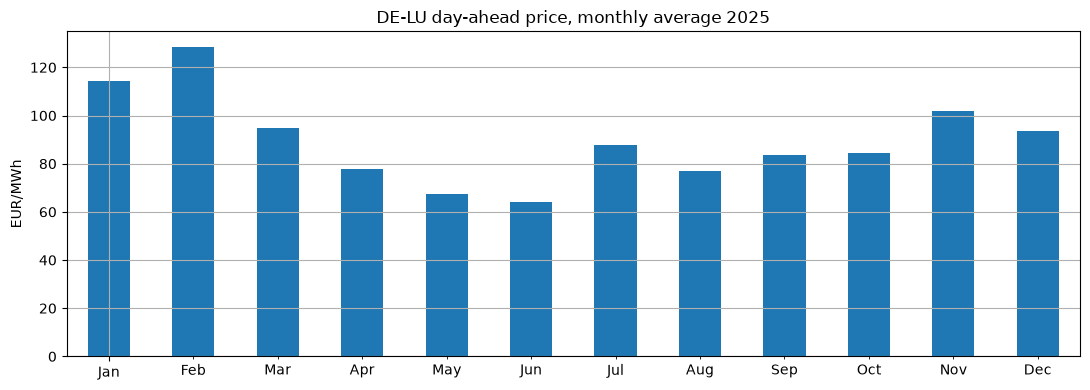

In [62]:
monthly = prices_de.resample("MS").mean()
ax = monthly.plot(kind="bar", color="tab:blue")
ax.set_xticklabels([d.strftime("%b") for d in monthly.index], rotation=0)
ax.set_ylabel("EUR/MWh")
ax.set_xlabel("")
ax.set_title(f"DE-LU day-ahead price, monthly average {YEAR}")
plt.tight_layout()

## 4. Price duration curve

All hours of the year sorted from the highest to the lowest price.
The tail on the right shows the hours with negative prices.

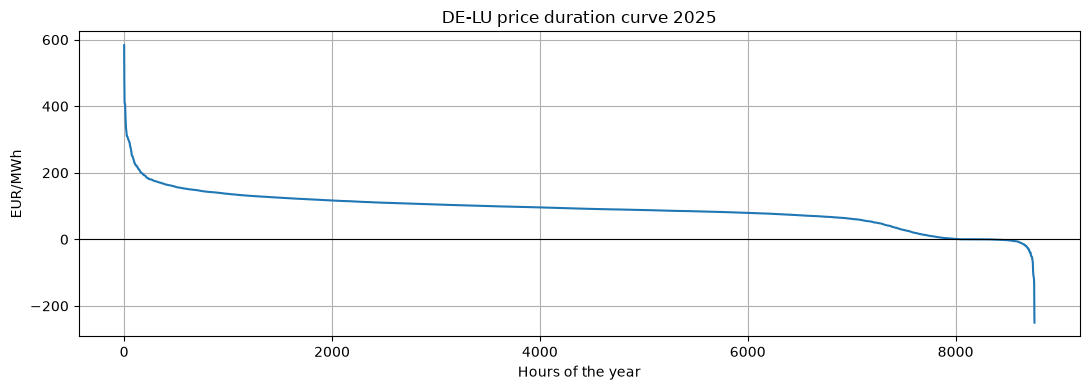

In [63]:
pdc = prices_de.sort_values(ascending=False).reset_index(drop=True)
ax = pdc.plot()
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Hours of the year")
ax.set_ylabel("EUR/MWh")
ax.set_title(f"DE-LU price duration curve {YEAR}")
plt.tight_layout()

## 5. Average price by hour of day and month

The midday dip in spring and summer is the solar effect.

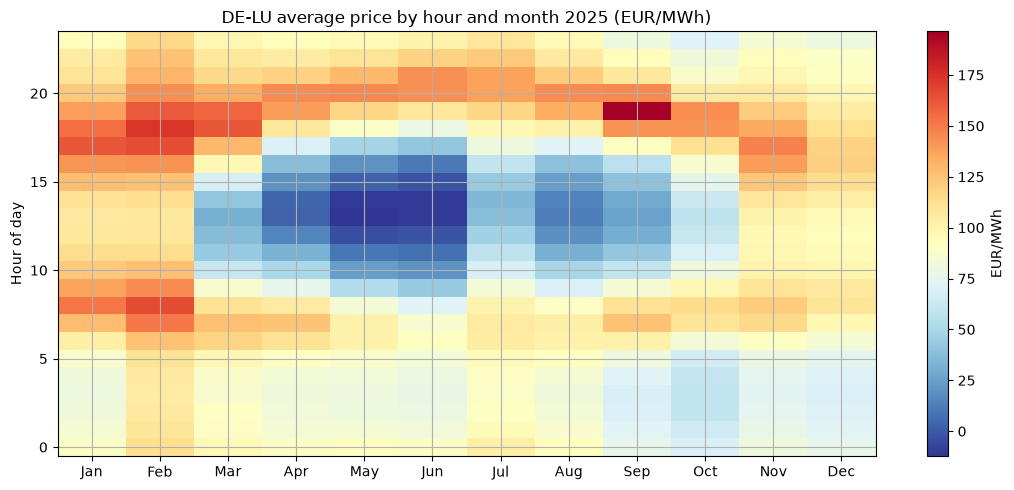

In [64]:
pivot = prices_de.groupby([prices_de.index.month, prices_de.index.hour]).mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pivot, aspect="auto", cmap="RdYlBu_r", origin="lower")
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Hour of day")
ax.set_title(f"DE-LU average price by hour and month {YEAR} (EUR/MWh)")
fig.colorbar(im, ax=ax, label="EUR/MWh")
plt.tight_layout()

## 6. Generation mix by month

C:\Users\apere\AppData\Local\Temp\ipykernel_44272\3878872782.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([d.strftime("%b") for d in mix.index], rotation=0)


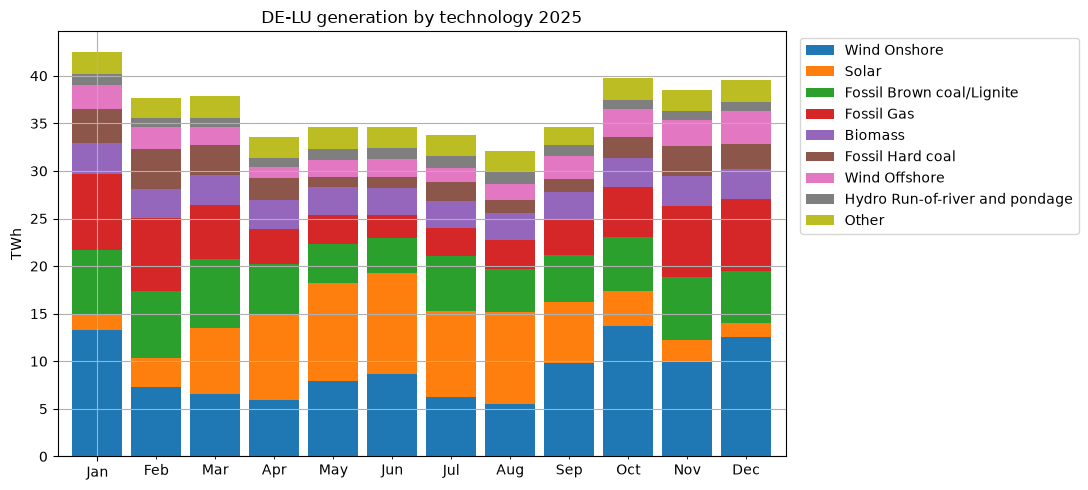

In [65]:
monthly_gen = gen_de.resample("MS").sum() / 1e6  # MWh -> TWh (hourly MW values)
# keep the largest technologies, group the rest
top = monthly_gen.sum().sort_values(ascending=False).index[:8]
mix = monthly_gen[top].copy()
mix["Other"] = monthly_gen.drop(columns=top).sum(axis=1)

ax = mix.plot(kind="bar", stacked=True, figsize=(11, 5), width=0.85)
ax.set_xticklabels([d.strftime("%b") for d in mix.index], rotation=0)
ax.set_ylabel("TWh")
ax.set_xlabel("")
ax.set_title(f"DE-LU generation by technology {YEAR}")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

In [66]:
annual_mix = (gen_de.sum() / 1e6).sort_values(ascending=False).round(1)
annual_mix.to_frame("TWh")

,TWh
Wind Onshore,107.2
Solar,74.2
Fossil Brown coal/Lignite,67.2
Fossil Gas,60.6
Biomass,36.1
Fossil Hard coal,28.2
Wind Offshore,26.2
Hydro Run-of-river and pondage,12.9
Hydro Pumped Storage,9.9
Waste,5.7


In [67]:
print("Generation:", round(gen_de.sum().sum() / 1e6, 1), "TWh")
print("Load:      ", round(load_de.sum() / 1e6, 1), "TWh")
print("Difference (≈ net imports):", round((load_de.sum() - gen_de.sum().sum()) / 1e6, 1), "TWh")

Generation: 439.2 TWh
Load:       470.7 TWh
Difference (≈ net imports): 31.4 TWh


## 7. Prices in neighbouring zones

Monthly averages for the zones of the planned model.

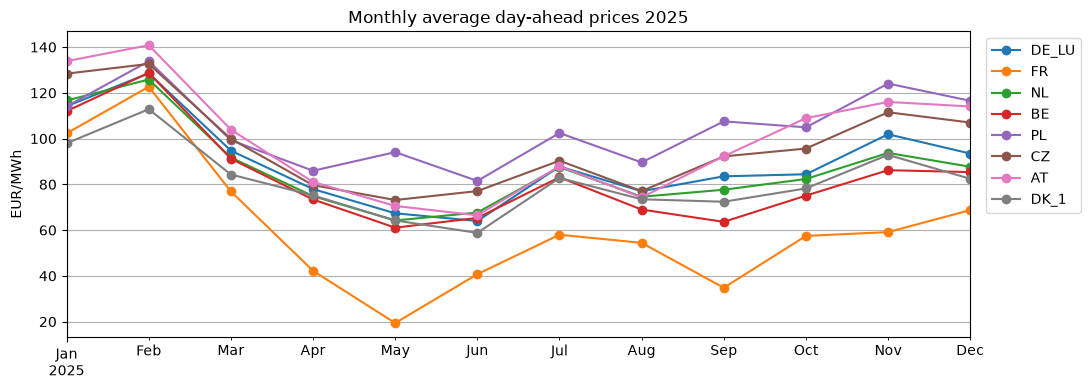

In [68]:
zones = ["DE_LU", "FR", "NL", "BE", "PL", "CZ", "AT", "DK_1"]
prices = {}
for z in zones:
    try:
        prices[z] = ed.day_ahead_prices(client, z, YEAR)
    except Exception as e:
        print(f"{z}: no data ({type(e).__name__})")
prices = pd.DataFrame(prices)

ax = prices.resample("MS").mean().plot(marker="o")
ax.set_ylabel("EUR/MWh")
ax.set_xlabel("")
ax.set_title(f"Monthly average day-ahead prices {YEAR}")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

In [69]:
prices.mean().sort_values().round(1).to_frame(f"Average price {YEAR} (EUR/MWh)")

,Average price 2025 (EUR/MWh)
FR,61.1
DK_1,81.1
BE,82.6
NL,86.8
DE_LU,89.3
CZ,96.8
AT,98.9
PL,104.3


In [72]:
top = pd.DataFrame({
    "Highest prices": prices_de.nlargest(10).round(1),
})
bottom = pd.DataFrame({
    "Lowest prices": prices_de.nsmallest(10).round(1),
})
display(top)
display(bottom)

,Highest prices
2025-01-20 17:00:00+01:00,583.4
2025-07-01 20:00:00+02:00,476.2
2025-01-20 18:00:00+01:00,473.3
2025-01-20 08:00:00+01:00,432.0
2025-09-08 19:00:00+02:00,413.7
2025-09-19 19:00:00+02:00,409.2
2025-10-14 19:00:00+02:00,407.2
2025-07-01 21:00:00+02:00,406.8
2025-09-29 19:00:00+02:00,406.8
2025-10-14 18:00:00+02:00,405.0


,Lowest prices
2025-05-11 13:00:00+02:00,-250.3
2025-05-11 14:00:00+02:00,-231.0
2025-05-11 12:00:00+02:00,-212.8
2025-05-01 13:00:00+02:00,-130.0
2025-04-27 13:00:00+02:00,-129.8
2025-05-01 14:00:00+02:00,-118.1
2025-04-27 14:00:00+02:00,-116.6
2025-04-06 14:00:00+02:00,-114.6
2025-05-10 13:00:00+02:00,-114.5
2025-05-10 14:00:00+02:00,-110.5


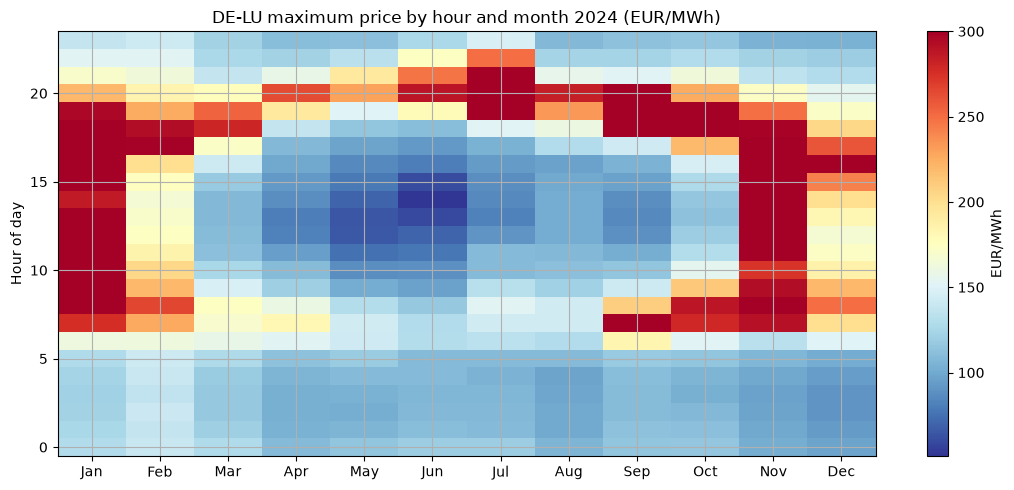

In [73]:
pivot_max = prices_de.groupby([prices_de.index.month, prices_de.index.hour]).max().unstack(0)
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pivot_max, aspect="auto", cmap="RdYlBu_r", origin="lower", vmax=300)
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Hour of day")
ax.set_title("DE-LU maximum price by hour and month 2024 (EUR/MWh)")
fig.colorbar(im, ax=ax, label="EUR/MWh")
plt.tight_layout()

## 8. Notes for the model

**Price level and spread (DE-LU, 2025)**
- Average 89.3 EUR/MWh, median 92.4 EUR/MWh, range −250.3 to 583.4 EUR/MWh.
- 576 hours with negative prices and 635 hours above 150 EUR/MWh: more volatile than 2024 at both ends.

**When prices are low and high**
- Negative and near-zero prices occur at midday from April to August, driven by solar.
- The highest prices occur in winter mornings and evenings (January–February) and in autumn evenings after sunset.

**Neighbouring zones**
- Price order: FR (61.1) < DK1 (81.1) < BE (82.6) < NL (86.8) < DE-LU (89.3) < CZ (96.8) < AT (98.9) < PL (104.3).
- France is far cheaper from April to September; Poland is the most expensive zone from summer onwards.

**Generation mix**
- Wind ~30% and solar ~17% of generation; lignite is stable all year; gas runs more in winter and sets the price more often then.

**Data handling**
- From October 2025, 15-minute day-ahead prices are averaged to hourly values.
- Missing hours: None.

**Checks for block 1**
- The model should reproduce the average price level, the midday solar dip, the winter and evening peaks, and the price order between zones.
- Scarcity peaks of several hundred EUR/MWh are not expected to be reproduced by a cost-based model.